## Lasso vs. Dantzig selector under weak and strong predictor correlation

**Model.** $y = X\beta^0+\varepsilon$, $\frac1n\|x_j\|_2^2=1$. After centering/standardizing with *training* quantities, all three objects below use the same scaling:

* Lasso: $\hat\beta^L(\lambda)\in\arg\min_\beta \frac{1}{2n}\|y-X\beta\|_2^2+\lambda\|\beta\|_1$ (this is exactly the `sklearn.linear_model.Lasso` objective with `fit_intercept=False`).
* Dantzig selector: $\hat\beta^D(\lambda)\in\arg\min_\beta \|\beta\|_1$ s.t. $\|\frac1n X^\top(y-X\beta)\|_\infty\le\lambda$, solved as a linear program.

With $G=X^\top X/n$ and $z=X^\top y/n$ the score is $\frac1nX^\top(y-X\beta)=z-G\beta$.

### 0. Setup, settings and reproducibility

In [1]:
import sys, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.optimize import linprog
from sklearn.linear_model import Lasso
from sklearn.exceptions import ConvergenceWarning

# Some macOS builds of NumPy 2.0.x (Accelerate BLAS) raise spurious floating-point-flag warnings
# ("divide by zero / overflow / invalid value encountered in matmul") even when every result is finite.
# We silence ONLY these matmul warnings, and instead verify finiteness explicitly (see run_rho).
warnings.filterwarnings("ignore", message=r".*encountered in matmul", category=RuntimeWarning)

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

# ---- settings (all reported) ----
SEED        = 607                 # master seed (same underlying draws used for both rho)
N_TRAIN, N_VAL, N_TEST = 160, 160, 2000
P, S        = 80, 10
RHOS        = [0.0, 0.85]
K_GRID      = 60                  # number of lambda values (>= 40 required)
LAM_MIN_RATIO = 1e-3              # lambda_min = 1e-3 * lambda_max, geometric grid
LASSO_TOL   = 1e-10               # sklearn coordinate-descent tolerance
LASSO_MAXIT = 500_000
LP_TOL      = 1e-9                # HiGHS primal/dual feasibility tolerance
THRESH      = 1e-6                # |coef| > THRESH counts as "selected"
EQ_TOL      = 1e-5                # |beta_L - beta_D| <= EQ_TOL counts as "equal"

BETA0 = np.zeros(P); BETA0[:10] = [3, 2.5, 2, 1.5, 1, -3, -2.5, -2, -1.5, -1]
SUPPORT = np.arange(10)

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__, "| sklearn", sklearn.__version__)
print(f"seed={SEED}, grid: {K_GRID} lambdas, geometric from lambda_max to {LAM_MIN_RATIO}*lambda_max")
print(f"Lasso: sklearn coordinate descent, tol={LASSO_TOL}, max_iter={LASSO_MAXIT}, warm starts along the path")
print(f"Dantzig: scipy.optimize.linprog(method='highs'), feasibility tol={LP_TOL}")
print(f"selection threshold={THRESH}, equality tolerance={EQ_TOL}")

python 3.9.6 | numpy 2.0.2 | scipy 1.13.1 | sklearn 1.6.1
seed=607, grid: 60 lambdas, geometric from lambda_max to 0.001*lambda_max
Lasso: sklearn coordinate descent, tol=1e-10, max_iter=500000, warm starts along the path
Dantzig: scipy.optimize.linprog(method='highs'), feasibility tol=1e-09
selection threshold=1e-06, equality tolerance=1e-05


### 1. Data generation and preprocessing (training-sample quantities only)

In [2]:
def make_data(rho, seed):
    # rows ~ N(0, Sigma_rho), (Sigma_rho)_{jk} = rho^{|j-k|}; eps ~ N(0,1).
    # Same seed for both rho => same underlying normal draws (common random numbers).
    rng = np.random.default_rng(seed)
    idx = np.arange(P)
    Sigma = rho ** np.abs(idx[:, None] - idx[None, :])
    L = np.linalg.cholesky(Sigma)
    def draw(n):
        X = rng.standard_normal((n, P)) @ L.T
        y = X @ BETA0 + rng.standard_normal(n)
        return X, y
    return draw(N_TRAIN), draw(N_VAL), draw(N_TEST)

def preprocess(tr, va, te):
    Xtr, ytr = tr
    xm, xs, ym = Xtr.mean(0), Xtr.std(0, ddof=0), ytr.mean()   # training quantities only
    f = lambda D: ((D[0] - xm) / xs, D[1] - ym)
    return f(tr), f(va), f(te), xs      # xs: to map coefficients back to the original scale

tr, va, te = make_data(0.85, SEED)
(trs, vas, tes, xs) = preprocess(tr, va, te)
Xtr, ytr = trs
print("train: mean|colmean| =", np.abs(Xtr.mean(0)).max().round(12), "| max |(1/n)||x_j||^2 - 1| =", np.abs((Xtr**2).mean(0) - 1).max().round(12), "| mean(y) =", ytr.mean().round(12))

train: mean|colmean| = 0.0 | max |(1/n)||x_j||^2 - 1| = 0.0 | mean(y) = 0.0


### 2. Solvers
Coefficients are fit on the standardized scale. For the $\ell_2$ error against $\beta^0$ we map back to the original predictor scale: $\hat\beta^{\text{orig}}_j=\hat\beta_j/s_j$, where $s_j$ is the training standard deviation.

In [3]:
def lam_grid(X, y):
    z = X.T @ y / len(y)
    lam_max = np.abs(z).max()
    return lam_max * np.geomspace(1.0, LAM_MIN_RATIO, K_GRID)      # decreasing

def lasso_path(X, y, lams):
    m = Lasso(alpha=lams[0], fit_intercept=False, tol=LASSO_TOL, max_iter=LASSO_MAXIT, warm_start=True)
    B, nconv = [], 0
    for lam in lams:
        m.set_params(alpha=lam)
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always", ConvergenceWarning)
            m.fit(X, y)
            nconv += any(issubclass(x.category, ConvergenceWarning) for x in w)
        B.append(m.coef_.copy())
    return np.array(B), nconv

def dantzig_one(G, z, lam):
    # beta = bp - bm, bp,bm >= 0 ; min 1'(bp+bm) s.t. -lam <= z - G beta <= lam
    p = len(z)
    A = np.block([[G, -G], [-G, G]])
    b = np.concatenate([lam + z, lam - z])
    res = linprog(np.ones(2 * p), A_ub=A, b_ub=b, bounds=(0, None), method="highs",
                  options={"primal_feasibility_tolerance": LP_TOL, "dual_feasibility_tolerance": LP_TOL})
    return res

def dantzig_path(X, y, lams):
    n = len(y); G = X.T @ X / n; z = X.T @ y / n
    B, bad = [], 0
    for lam in lams:
        r = dantzig_one(G, z, lam)
        bad += (r.status != 0)
        B.append(r.x[:P] - r.x[P:] if r.status == 0 else np.full(P, np.nan))
    return np.array(B), bad

def max_violation(X, y, B, lams):
    # max(0, ||(1/n)X'(y-X beta)||_inf - lambda) for each row of B
    n = len(y); G = X.T @ X / n; z = X.T @ y / n
    sc = np.abs(z[None, :] - B @ G).max(1)           # G symmetric
    return np.maximum(0.0, sc - lams), sc

### 3. Per-$\rho$ fit, validation-based selection of $\lambda$, and test evaluation

In [4]:
def run_rho(rho, seed=SEED, verbose=True):
    tr, va, te = make_data(rho, seed)
    (Xtr, ytr), (Xva, yva), (Xte, yte), xs = preprocess(tr, va, te)
    # explicit finiteness checks: if a matmul warning were REAL, these would fail
    for nm, A in [("Xtr", Xtr), ("ytr", ytr), ("Xva", Xva), ("yva", yva), ("Xte", Xte), ("yte", yte)]:
        assert np.isfinite(A).all(), f"non-finite values in {nm}"
    lams = lam_grid(Xtr, ytr)
    t0 = time.time(); BL, nconv = lasso_path(Xtr, ytr, lams); tL = time.time() - t0
    t0 = time.time(); BD, nbad  = dantzig_path(Xtr, ytr, lams); tD = time.time() - t0
    assert np.isfinite(BL).all(), "non-finite Lasso coefficients"
    assert nbad == 0 and np.isfinite(BD).all(), "Dantzig LP failed or returned non-finite coefficients"
    out = dict(rho=rho, lams=lams, BL=BL, BD=BD, xs=xs, Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, Xte=Xte, yte=yte,
               n_not_converged=nconv, n_lp_failed=nbad, tL=tL, tD=tD)
    for name, B in [("L", BL), ("D", BD)]:
        out["val_" + name]  = ((yva[None, :] - B @ Xva.T) ** 2).mean(1)
        out["test_" + name] = ((yte[None, :] - B @ Xte.T) ** 2).mean(1)
        out["viol_" + name], out["score_" + name] = max_violation(Xtr, ytr, B, lams)
        out["i_" + name] = int(np.nanargmin(out["val_" + name]))
    if verbose:
        print(f"rho={rho}: Lasso {tL:.1f}s (non-converged fits: {nconv}), Dantzig {tD:.1f}s (LP failures: {nbad})")
    return out

def metrics(res, name):
    i = res["i_" + name]; B = res["BL"] if name == "L" else res["BD"]
    b = B[i]; b_orig = b / res["xs"]
    sel = np.abs(b) > THRESH
    return {"lambda*": res["lams"][i], "test MSE": res["test_" + name][i], "val MSE": res["val_" + name][i],
            "l2 coef err": np.linalg.norm(b_orig - BETA0),
            "TP": int(sel[SUPPORT].sum()), "FP": int(sel[S:].sum()), "size": int(sel.sum()),
            "l1 norm": np.abs(b).sum(), "max score viol": res["viol_" + name][i]}

RES = {rho: run_rho(rho) for rho in RHOS}

rho=0.0: Lasso 0.1s (non-converged fits: 0), Dantzig 0.4s (LP failures: 0)
rho=0.85: Lasso 0.1s (non-converged fits: 0), Dantzig 0.4s (LP failures: 0)


### 4. Main results at the validation-selected $\lambda$ (test sample used only here)

In [5]:
rows = []
for rho, res in RES.items():
    for name, lab in [("L", "Lasso"), ("D", "Dantzig")]:
        rows.append({"rho": rho, "method": lab, **metrics(res, name)})
TABLE = pd.DataFrame(rows).set_index(["rho", "method"])
TABLE.round({"lambda*": 4, "test MSE": 4, "val MSE": 4, "l2 coef err": 4, "l1 norm": 4, "max score viol": 10})

lambda*  test MSE  val MSE  l2 coef err  TP  FP  size  l1 norm  max score viol
rho  method                                                                                 
0.00 Lasso     0.0672    1.2452   0.9816       0.4601  10  29    39  19.7368    1.000000e-10
     Dantzig   0.0598    1.2729   0.9776       0.4719  10  32    42  20.0842    0.000000e+00
0.85 Lasso     0.0597    1.2155   1.0093       1.0628  10  18    28  18.5448    1.000000e-10
     Dantzig   0.0332    1.3430   1.1197       1.4644  10  20    30  19.6763    0.000000e+00

In [6]:
print("l1 norm is on the standardized scale (the scale on which both estimators are fit); l2 coef err is on the original predictor scale.")
print("Oracle benchmark: test MSE of the true beta0 on this test set (noise variance ~ 1):")
for rho, res in RES.items():
    Xte, yte, xs = res["Xte"], res["yte"], res["xs"]
    print(f"  rho={rho}: test MSE at beta0 = {((yte - Xte @ (BETA0 * xs))**2).mean():.4f}")

l1 norm is on the standardized scale (the scale on which both estimators are fit); l2 coef err is on the original predictor scale.
Oracle benchmark: test MSE of the true beta0 on this test set (noise variance ~ 1):
  rho=0.0: test MSE at beta0 = 1.0207
  rho=0.85: test MSE at beta0 = 1.0207


### 5. Path comparison, feasibility and convergence checks

In [7]:
def path_diagnostics(res):
    lams, BL, BD = res["lams"], res["BL"], res["BD"]
    gap = np.abs(BL - BD).max(1)                               # max_j |bL_j - bD_j| per lambda
    supL, supD = np.abs(BL) > THRESH, np.abs(BD) > THRESH
    same_sup = (supL == supD).all(1)
    jac = np.array([(a & b).sum() / max((a | b).sum(), 1) for a, b in zip(supL, supD)])
    l1L, l1D = np.abs(BL).sum(1), np.abs(BD).sum(1)
    return dict(gap=gap, equal=gap <= EQ_TOL, same_sup=same_sup, jac=jac, l1L=l1L, l1D=l1D)

def theorem2_condition(X, B, tol=1e-8):
    # Sufficient condition (8) of James-Radchenko-Lv for beta_L == beta_D at lambda_L = lambda_D.
    # Paper uses unit-norm columns: X/sqrt(n) here. X_L = columns of lasso support times coefficient signs.
    n = X.shape[0]; Xs = X / np.sqrt(n); out = []
    for b in B:
        I = np.where(np.abs(b) > THRESH)[0]
        if len(I) == 0: out.append(True); continue
        XL = Xs[:, I] * np.sign(b[I])
        M = XL.T @ XL
        if np.linalg.matrix_rank(XL) < len(I): out.append(False); continue
        u = np.linalg.solve(M, np.ones(len(I)))
        ok = (u >= -tol).all() and (np.abs(Xs.T @ (XL @ u)).max() <= 1 + tol)
        out.append(bool(ok))
    return np.array(out)

DIAG = {}
summ = []
for rho, res in RES.items():
    d = path_diagnostics(res); d["thm2"] = theorem2_condition(res["Xtr"], res["BL"]); DIAG[rho] = d
    iL, iD = res["i_L"], res["i_D"]
    summ.append({"rho": rho,
                 "# lambdas": K_GRID,
                 "# equal (|gap|<=tol)": int(d["equal"].sum()),
                 "max path gap": d["gap"].max(),
                 "# identical supports": int(d["same_sup"].sum()),
                 "mean Jaccard(supp)": d["jac"].mean(),
                 "# Thm-2 cond. holds": int(d["thm2"].sum()),
                 "Thm-2 holds => equal (violations)": int((d["thm2"] & ~d["equal"]).sum()),
                 "max Lasso score viol": res["viol_L"].max(),
                 "max Dantzig score viol": res["viol_D"].max(),
                 "max |l1_L - l1_D| (D<=L?)": float(np.nanmax(d["l1L"] - d["l1D"])),
                 "min (l1_L - l1_D)": float(np.nanmin(d["l1L"] - d["l1D"])),
                 "Lasso fits not converged": res["n_not_converged"], "LP failures": res["n_lp_failed"],
                 "selected lambdas equal?": bool(iL == iD),
                 "gap at selected lambdas": float(np.abs(res["BL"][iL] - res["BD"][iD]).max())})
pd.DataFrame(summ).set_index("rho").T

rho,0.00,0.85
# lambdas,60,60
# equal (|gap|<=tol),32,5
max path gap,0.086692,3.11916
# identical supports,32,8
mean Jaccard(supp),0.937987,0.721673
# Thm-2 cond. holds,32,5
Thm-2 holds => equal (violations),0,0
max Lasso score viol,0.0,0.0
max Dantzig score viol,0.0,0.0
max |l1_L - l1_D| (D<=L?),0.22377,0.796685


### 6. Figures

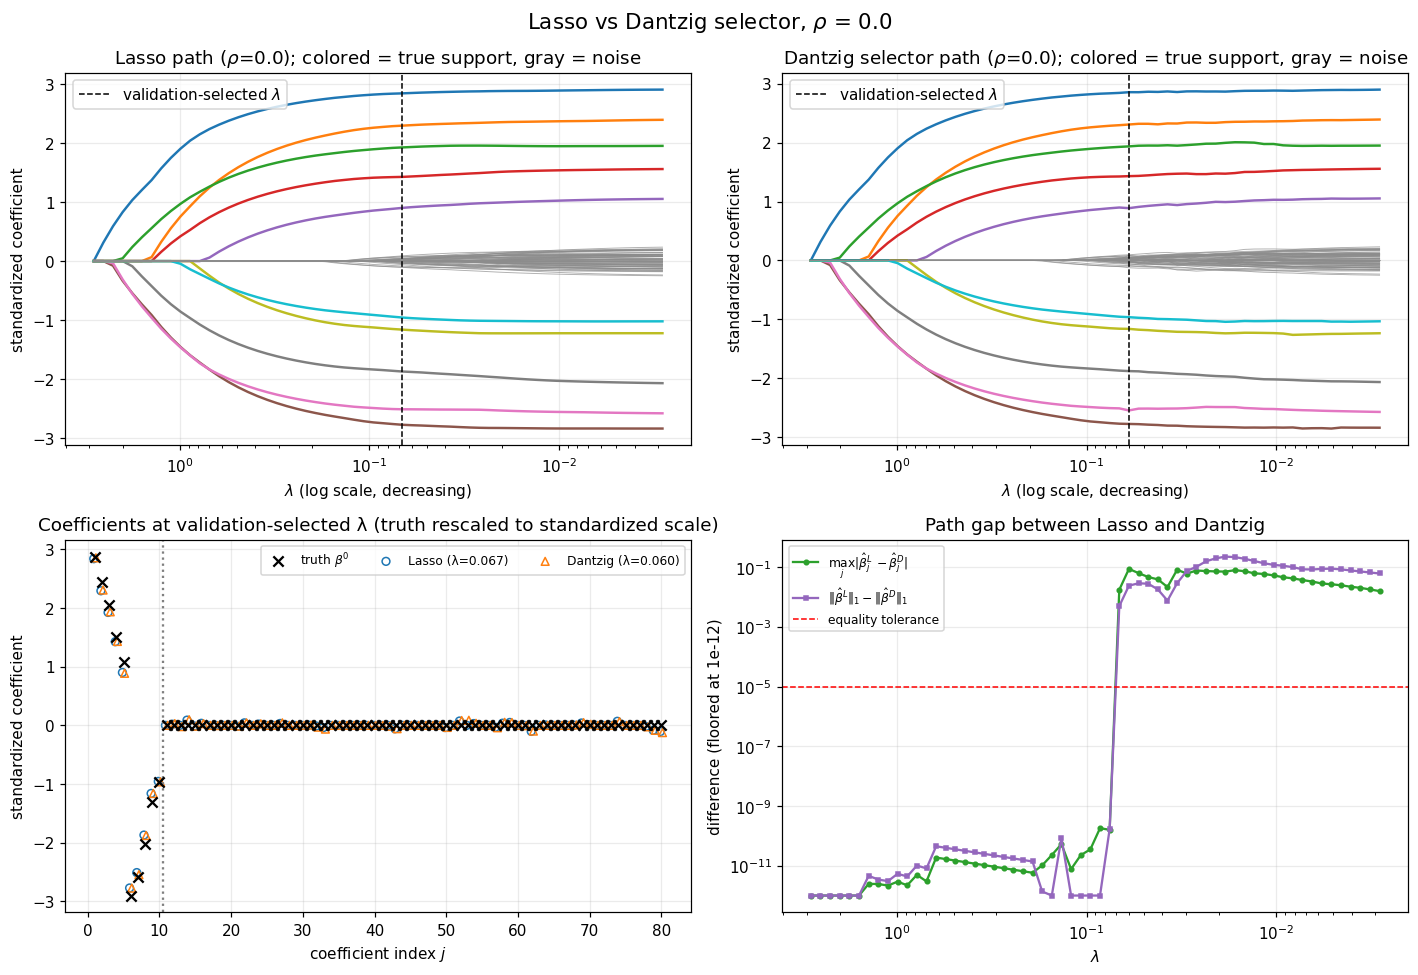

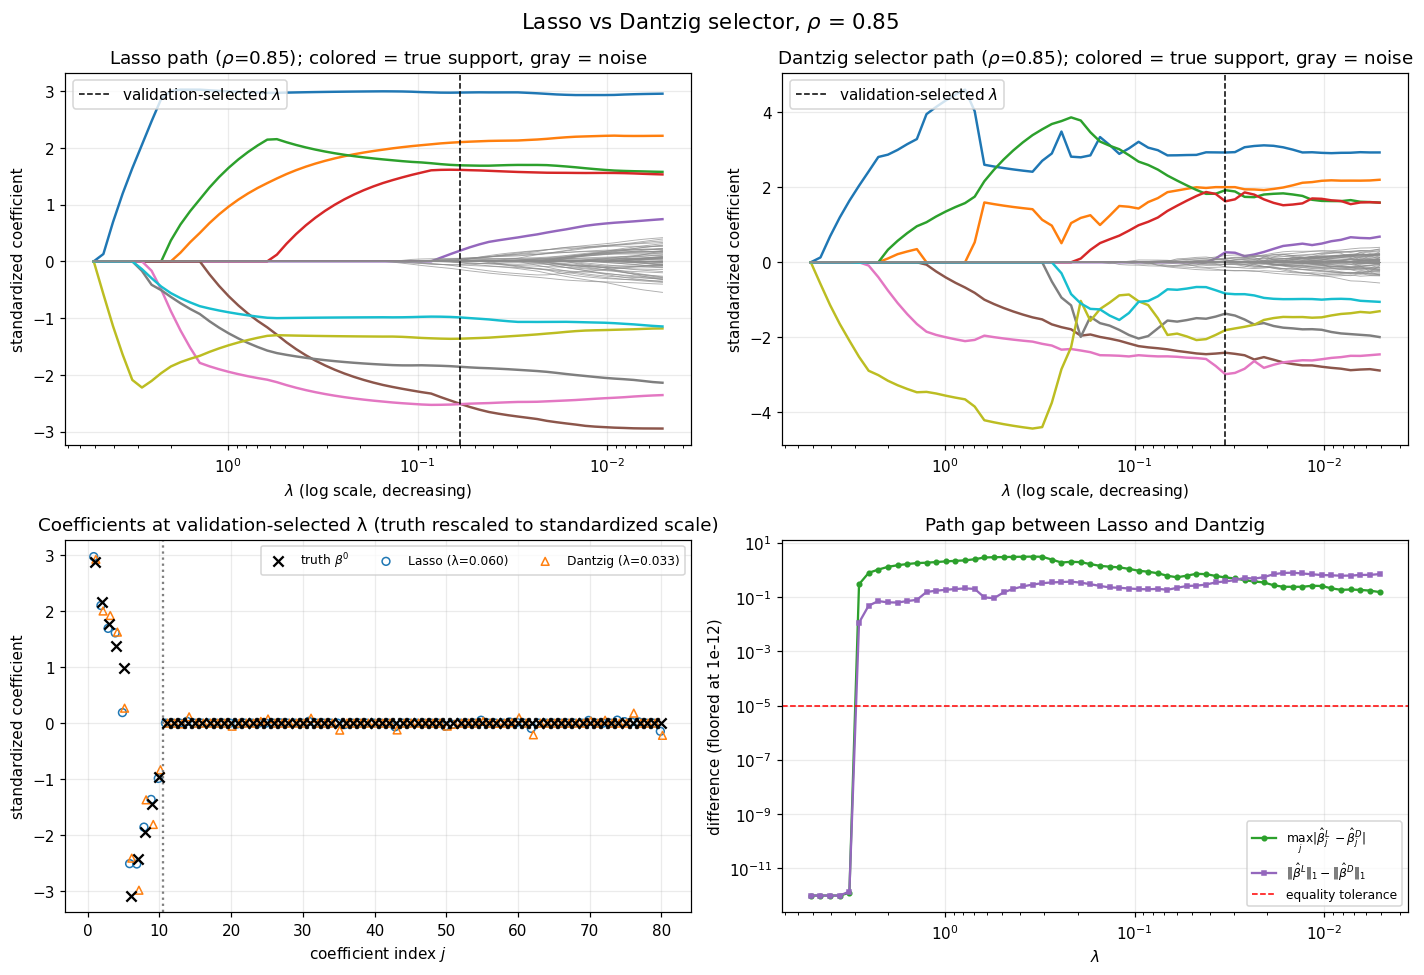

In [8]:
def fig_rho(rho):
    res = RES[rho]; d = DIAG[rho]; lams = res["lams"]
    iL, iD = res["i_L"], res["i_D"]
    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    for a, B, ttl, i in [(ax[0, 0], res["BL"], "Lasso path", iL), (ax[0, 1], res["BD"], "Dantzig selector path", iD)]:
        for j in range(P):
            if j in SUPPORT: a.plot(lams, B[:, j], lw=1.6, color=plt.cm.tab10(j % 10))
            else:            a.plot(lams, B[:, j], lw=.6, color="0.55", alpha=.7)
        a.axvline(lams[i], color="k", ls="--", lw=1, label=r"validation-selected $\lambda$")
        a.set_xscale("log"); a.invert_xaxis(); a.set_xlabel(r"$\lambda$ (log scale, decreasing)"); a.set_ylabel("standardized coefficient")
        a.set_title(f"{ttl} ($\\rho$={rho}); colored = true support, gray = noise"); a.legend(loc="upper left")
    a = ax[1, 0]
    ob = BETA0 * res["xs"]
    a.scatter(np.arange(1, P + 1), ob, marker="x", c="k", s=45, label=r"truth $\beta^0$", zorder=3)
    a.scatter(np.arange(1, P + 1) - .15, res["BL"][iL], marker="o", s=26, facecolors="none", edgecolors="tab:blue", label=f"Lasso (λ={lams[iL]:.3f})")
    a.scatter(np.arange(1, P + 1) + .15, res["BD"][iD], marker="^", s=26, facecolors="none", edgecolors="tab:orange", label=f"Dantzig (λ={lams[iD]:.3f})")
    a.axvline(S + .5, color="0.5", ls=":"); a.set_xlabel("coefficient index $j$"); a.set_ylabel("standardized coefficient")
    a.set_title("Coefficients at validation-selected λ (truth rescaled to standardized scale)"); a.legend(ncol=3, fontsize=8)
    a = ax[1, 1]
    a.semilogy(lams, np.maximum(d["gap"], 1e-12), "o-", ms=3, color="tab:green", label=r"$\max_j|\hat\beta^L_j-\hat\beta^D_j|$")
    a.semilogy(lams, np.maximum(d["l1L"] - d["l1D"], 1e-12), "s-", ms=3, color="tab:purple", label=r"$\|\hat\beta^L\|_1-\|\hat\beta^D\|_1$")
    a.axhline(EQ_TOL, color="r", ls="--", lw=1, label="equality tolerance")
    a.set_xscale("log"); a.invert_xaxis(); a.set_xlabel(r"$\lambda$"); a.set_ylabel("difference (floored at 1e-12)")
    a.set_title("Path gap between Lasso and Dantzig"); a.legend(fontsize=8)
    fig.suptitle(rf"Lasso vs Dantzig selector, $\rho$ = {rho}", fontsize=14); fig.tight_layout()
    plt.show()

for rho in RHOS: fig_rho(rho)

### 7. Supplementary: Monte-Carlo replication of the comparison (robustness of the single-dataset conclusions)
The main analysis above uses one dataset per $\rho$, as specified. Because a single draw can mislead, we repeat the entire pipeline (new data, new validation selection) for $R$ independent seeds and summarize.

In [9]:
R = 20
def one_rep(rho, seed):
    res = run_rho(rho, seed, verbose=False); d = path_diagnostics(res)
    mL, mD = metrics(res, "L"), metrics(res, "D")
    return {"rho": rho, "seed": seed,
            "mse_L": mL["test MSE"], "mse_D": mD["test MSE"], "l2_L": mL["l2 coef err"], "l2_D": mD["l2 coef err"],
            "size_L": mL["size"], "size_D": mD["size"], "FP_L": mL["FP"], "FP_D": mD["FP"], "TP_L": mL["TP"], "TP_D": mD["TP"],
            "frac_equal_grid": d["equal"].mean(), "frac_same_support_grid": d["same_sup"].mean(),
            "max_gap": d["gap"].max(), "equal_at_selected": float(np.abs(res["BL"][res["i_L"]] - res["BD"][res["i_D"]]).max() <= EQ_TOL)}
t0 = time.time()
REPS = pd.DataFrame([one_rep(rho, SEED + 1000 + r) for rho in RHOS for r in range(R)])
print(f"{R} replications x {len(RHOS)} rho in {time.time()-t0:.0f}s")
agg = REPS.groupby("rho").agg(["mean", "std"]).drop(columns="seed")
agg.columns = [f"{a}_{b}" for a, b in agg.columns]
agg.T.round(4)

20 replications x 2 rho in 19s


rho,0.00,0.85
mse_L_mean,1.2430,1.1958
mse_L_std,0.0802,0.0971
mse_D_mean,1.2437,1.2575
mse_D_std,0.0820,0.0897
l2_L_mean,0.4755,0.8581
l2_L_std,0.0512,0.2364
l2_D_mean,0.4767,1.0489
l2_D_std,0.0538,0.2635
size_L_mean,29.4500,27.8500
size_L_std,8.5253,7.9689


In [10]:
# Paired differences (Dantzig minus Lasso) within each replication: same data, so pairing removes data-to-data variability
P_ = REPS.assign(d_mse=REPS.mse_D - REPS.mse_L, d_l2=REPS.l2_D - REPS.l2_L, d_size=REPS.size_D - REPS.size_L)
paired = P_.groupby("rho").agg(
    d_mse_mean=("d_mse", "mean"), d_mse_se=("d_mse", lambda x: x.std() / np.sqrt(len(x))), frac_D_worse_mse=("d_mse", lambda x: (x > 0).mean()),
    d_l2_mean=("d_l2", "mean"), d_l2_se=("d_l2", lambda x: x.std() / np.sqrt(len(x))), frac_D_worse_l2=("d_l2", lambda x: (x > 0).mean()),
    d_size_mean=("d_size", "mean"))
paired.T.round(4)

rho,0.00,0.85
d_mse_mean,0.0006,0.0617
d_mse_se,0.0025,0.0159
frac_D_worse_mse,0.5000,0.8500
d_l2_mean,0.0012,0.1908
d_l2_se,0.0027,0.0516
frac_D_worse_l2,0.5500,0.7500
d_size_mean,-0.2000,4.4500
